# Laborator 6, Exercițiul 1
## Care este rata medie de apeluri a unui call center?

Numărul de apeluri pe oră este Poisson $(\lambda)$. În $n = 10$ ore s-au primit $180$ de apeluri, deci $\sum_t y_t = 180$. Vrem distribuția *a posteriori* a lui $\lambda$, un HDI de $94\%$ și cea mai probabilă valoare a lui $\lambda$.

### Notații

- $\lambda$: rata medie de apeluri pe oră (parametrul necunoscut, $\lambda > 0$);
- $X$:  numărul de apeluri într-o oră, $X \sim \text{Poisson}(\lambda)$;
- $y_t$:  numărul de apeluri observat în ora $t$;
- $n$:  numărul de ore observate ($n = 10$);
- $\sum_t y_t$:  totalul apelurilor observate ($= 180$);
- $y$:  datele observate (toate $y_t$ împreună);
- $\alpha, \beta$:  parametrii priorului Gamma ($\alpha, \beta > 0$);
- $p(\lambda)$:  priorul, $p(y \mid \lambda)$:  verosimilitatea, $p(\lambda \mid y)$:  posteriorul;
- $\Gamma(\cdot)$:  funcția Gamma (constanta de normalizare a densității Gamma).

### Derivarea posteriorului

Pmf-ul **Poisson** cu parametrul $\lambda > 0$ (verosimilitatea unei observații):

$$P(X = k) = e^{-\lambda}\frac{\lambda^{k}}{k!}, \qquad k = 0, 1, 2, \dots$$

Densitatea **Gamma** cu parametrii $\alpha, \beta > 0$ (priorul pentru $\lambda$):

$$p(\lambda) = \frac{\beta^{\alpha}}{\Gamma(\alpha)}\,\lambda^{\alpha-1}\,e^{-\beta\lambda}, \qquad \lambda > 0.$$

Posteriorul îl derivăm din $p(\lambda \mid y) \propto p(y \mid \lambda)\, p(\lambda)$.

" $\propto$ " înseamnă că putem ignora orice factor care nu depinde de $\lambda$.

Observațiile sunt independente condiționat de $\lambda$, deci verosimilitatea comună este doar produsul:

$$p(y \mid \lambda) = \prod_{t=1}^{n} e^{-\lambda}\frac{\lambda^{y_t}}{y_t!} \;\propto\; \lambda^{\sum_t y_t}\, e^{-n\lambda}.$$

Factorul $\frac{\beta^{\alpha}}{\Gamma(\alpha)}$ este o constantă în raport cu $\lambda$:

$$p(\lambda) \propto \lambda^{\alpha-1}\, e^{-\beta\lambda}.$$

$$p(\lambda \mid y) \propto \lambda^{\sum_t y_t}\, e^{-n\lambda} \cdot \lambda^{\alpha-1}\, e^{-\beta\lambda} = \lambda^{(\alpha+\sum_t y_t)-1}\, e^{-(\beta+n)\lambda}.$$

Aceasta are exact forma $\lambda^{a-1}e^{-b\lambda}$ a unei Gamma:

$$\lambda \mid y \sim \text{Gamma}\Big(\alpha + \textstyle\sum_t y_t,\ \beta + n\Big).$$

### Alegerea parametrilor și valorile

Media priorului Gamma este $\alpha/\beta$. Alegem $\alpha = 18$, $\beta = 1$, deci media prior $= 18$ cu varianță mare ($\alpha/\beta^2 = 18$).

Pentru multe observații, datele domină frecvent influența priorului, și avertizează că un prior prea restrictiv sau nepotrivit este o problemă. Cu un prior larg și $n = 10$ ore de date, lăsăm observațiile să determine rezultatul.

Înlocuind $\sum_t y_t = 180$ și $n = 10$:

$$\lambda \mid y \sim \text{Gamma}(18 + 180,\ 1 + 10) = \text{Gamma}(198,\ 11).$$

Cea mai probabilă valoare este modul, $(\alpha_\text{post}-1)/\beta_\text{post} = 197/11$; HDI-ul de $94\%$ se calculează numeric.

posterior: Gamma(alpha=198, beta=11)
cea mai probabila valoare (mod) = 17.909
HDI 94% = [15.611, 20.420]


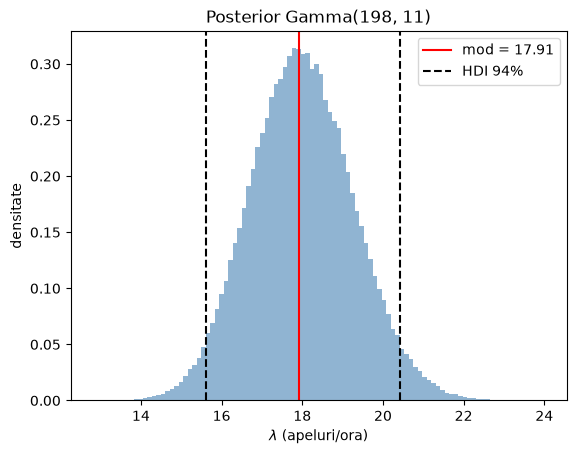

In [ ]:
import numpy as np
import arviz as az

total, ore = 180, 10          # sum_t y_t si n
alpha0, beta0 = 18.0, 1.0     # prior Gamma

alpha_post = alpha0 + total   # alpha + sum y_t
beta_post = beta0 + ore       # beta + n

# esantion din posterior pentru HDI (Gamma nu are HDI in forma inchisa)
rng = np.random.default_rng(0)
post = rng.gamma(shape=alpha_post, scale=1 / beta_post, size=200_000)

mod = (alpha_post - 1) / beta_post
hdi = az.hdi(post, prob=0.94)

print(f"posterior: Gamma(alpha={alpha_post:.0f}, beta={beta_post:.0f})")
print(f"cea mai probabila valoare (mod) = {mod:.3f}")
print(f"HDI 94% = [{hdi[0]:.3f}, {hdi[1]:.3f}]")

# vizualizare: histograma esantionului din posterior + mod si HDI
import matplotlib.pyplot as plt

plt.hist(post, bins=100, density=True, color="steelblue", alpha=0.6)
plt.axvline(mod, color="red", label=f"mod = {mod:.2f}")
plt.axvline(hdi[0], color="black", ls="--")
plt.axvline(hdi[1], color="black", ls="--", label="HDI 94%")
plt.xlabel("$\\lambda$ (apeluri/ora)"); plt.ylabel("densitate")
plt.title("Posterior Gamma(198, 11)"); plt.legend()
plt.show()


Posteriorul este Gamma $(198, 11)$: cea mai probabilă rată este $\approx 17.9$ apeluri/oră, iar cu probabilitate $94\%$ rata reală se află în HDI-ul $\approx [15.6,\ 20.4]$.